# DIFA Velachery — BDM Capstone, Final Analysis

**Rohit Raj · 23f2002469 · IITM Online BS Degree Programme**

This notebook produces every figure and every number quoted in my final report. It carries on from
the cleaning work I did for the mid-term report: it starts from the `Clean data` sheet I built there
and does not repeat the cleaning steps.

**What is in here**

| Part | What it does | Report output |
|---|---|---|
| 0 | Setup and helper functions | — |
| 1 | Load the sheet and apply the category correction (89 labels → 38 categories) | Table 2 |
| 2 | Chart 0 — overall revenue and units trend | Figure 3 |
| 3 | Chart 1 — category portfolio screen | Figure 4 |
| 4 | Chart 2 — row-normalised monthly sales mix | Figure 5 |
| 5 | Chart 3 — revenue mix by category and MRP band | Figure 6 |
| 6 | Chart 4 — change in average monthly category revenue | Figure 7 |
| 7 | Chart 5 — ABC classification | Figure 8, Table 4 |
| 8 | Chart 6 — earring sub-type deep dive | Figure 9, Table 5 |
| 9 | Influencer scoring, corrected | Figures 10–11, Tables 6–7 |
| 10 | Self-audit: reconciliation bridge and headline checks | Table 1 |

**Two definitions drive everything**

- **Revenue** = `Item Net Amount` — already *net* of returns, because a return is written into the file
  as a negative quantity and a negative amount on the same product, so it subtracts itself.
- **Units** = `Sold Qty` — also net.

**Two rules I apply everywhere**

1. Only the eight **full months, April–November 2025**. December 2025 is one trading week
   (593 records) because the owner exported the file on 7 December 2025, so I drop it from every
   trend, average, comparison and chart.
2. The **category correction**: all `CS-NP-*` item codes become one `NAIL POLISH` category, and
   boxes, paper bags and size-coded pouches are excluded as packaging rather than merchandise.
   `NECK TRAY - SMALL` stays in.

Set `DATA_PATH` below to your copy of the workbook, then Run All.

## 0 — Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
import seaborn as sns                 # pip install seaborn if needed
from pathlib import Path
import os

# --- point this at the workbook the owner shared -----------------------------
DATA_PATH = Path('Business sales data.xlsx')
if not DATA_PATH.exists():
    DATA_PATH = Path('BDM project/Business sales data.xlsx')
if not DATA_PATH.exists():
    raise FileNotFoundError('Business sales data.xlsx was not found. Update DATA_PATH.')

INFL_PATH = Path('Nift students.xlsx')          # manually collected candidate sheet
SHEET     = 'Clean data'
OUT       = DATA_PATH.parent / 'charts'
os.makedirs(OUT, exist_ok=True)

plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.edgecolor':'#444',
                     'axes.linewidth':0.8,'figure.dpi':120,'savefig.dpi':220,'savefig.bbox':'tight'})
INK='#1f2a44'; ACC='#2a6f97'; GOOD='#2a9d5c'; BAD='#c1443c'; WARN='#e0a83b'; GREY='#9aa3ad'

def inr(x, _=None):
    '''Short rupee label for chart axes: 1.2Cr / 3.4L / 56K / 78.'''
    if abs(x) >= 1e7: return f'\u20b9{x/1e7:.1f}Cr'
    if abs(x) >= 1e5: return f'\u20b9{x/1e5:.1f}L'
    if abs(x) >= 1e3: return f'\u20b9{x/1e3:.0f}K'
    return f'\u20b9{x:.0f}'

def ind(n, dec=0):
    '''Indian digit grouping: 10539048 -> 1,05,39,048.'''
    neg = n < 0; n = abs(n)
    w, _, fr = f'{n:,.{dec}f}'.partition('.')
    w = w.replace(',', '')
    if len(w) > 3:
        head, tail, parts = w[:-3], w[-3:], []
        while len(head) > 2:
            parts.insert(0, head[-2:]); head = head[:-2]
        if head: parts.insert(0, head)
        w = ','.join(parts + [tail])
    return ('-' if neg else '') + w + ('.' + fr if fr else '')

def savefig(name):
    plt.savefig(OUT / name, facecolor='white')

print('setup done \u2014 charts will be written to', OUT.resolve())

setup done — charts will be written to /home/claude/nbrun/charts


## 1 — Load and apply the category correction

I strip whitespace on the text columns and force the three numeric columns to be numeric, then build
`f`, the working frame: eight full months, packaging removed, nail-polish codes combined.

The two `assert` lines are there on purpose. If somebody re-runs this on a fresh export and a month is
missing, or a revenue/quantity/MRP value is blank, I want the notebook to stop rather than quietly
produce a chart that is wrong.

In [2]:
df = pd.read_excel(DATA_PATH, sheet_name=SHEET)

# the sheet has a few trailing blank rows; 17,898 valid records remain
df = df.dropna(subset=['Month','Item Category','Sold Qty','Item Net Amount','MRP'])

for col in ['Item Category','SUB CATEGORY','COLOUR','Month']:
    df[col] = df[col].astype(str).str.strip()
for col in ['Sold Qty','Item Net Amount','MRP']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

MONTHS = ['April 2025','May 2025','June 2025','July 2025','August 2025',
          'September 2025','October 2025','November 2025']
MLAB   = ['Apr','May','Jun','Jul','Aug','Sep','Oct','Nov']

# --- the category correction -------------------------------------------------
# CS-NP-nnn are nail-polish SHADES, not categories -> collapse to one category
# BOX / PAPER BAG / POUCH with a size code are packaging, not merchandise -> exclude
NON_MERCH = r'^(?:PAPER BAG S\d+|BOX[ -]\d+|POUCH[ -]S\d+)$'
df['Analysis Category'] = np.where(df['Item Category'].str.match(r'^CS-NP-', na=False),
                                   'NAIL POLISH', df['Item Category'])
df['Non-merchandise']   = df['Item Category'].str.match(NON_MERCH, na=False)

f = df[df['Month'].isin(MONTHS) & ~df['Non-merchandise']].copy()

assert set(MONTHS).issubset(set(df['Month'])), 'One or more full months is missing.'
assert f[['Sold Qty','Item Net Amount','MRP']].notna().all().all(), 'Numeric fields contain missing values.'

# per-category summary used by several charts below
cat = (f.groupby('Analysis Category')
         .agg(units=('Sold Qty','sum'), rev=('Item Net Amount','sum'), skus=('U-ID','nunique'))
         .reset_index())
cat = cat[cat['units'] > 0].copy()
cat['realised'] = cat['rev'] / cat['units']       # realised price = revenue / units

excluded = df[df['Month'].isin(MONTHS) & df['Non-merchandise']]

print('--- Table 2: the category correction, step by step ---')
print(f"raw category labels on the clean sheet   : {df['Item Category'].nunique()}")
print(f"  of which CS-NP-* nail polish codes     : {df.loc[df['Item Category'].str.match('^CS-NP-', na=False),'Item Category'].nunique()}  -> combined into 1")
print(f"  of which packaging labels excluded     : {excluded['Item Category'].nunique()}")
print(f"customer-merchandise categories used     : {len(cat)}")
print()
print(f"Apr-Nov merchandise revenue              : \u20b9{ind(cat['rev'].sum())}")
print(f"Apr-Nov net units                        : {ind(f['Sold Qty'].sum())}")
print(f"active product identifiers (U-IDs)       : {ind(f['U-ID'].nunique())}")
print(f"excluded packaging                       : {ind(excluded['Sold Qty'].sum())} units / \u20b9{ind(excluded['Item Net Amount'].sum())}")

--- Table 2: the category correction, step by step ---
raw category labels on the clean sheet   : 89
  of which CS-NP-* nail polish codes     : 37  -> combined into 1
  of which packaging labels excluded     : 15
customer-merchandise categories used     : 38

Apr-Nov merchandise revenue              : ₹1,05,39,048
Apr-Nov net units                        : 81,520
active product identifiers (U-IDs)       : 5,813
excluded packaging                       : 338 units / ₹9,732


## 2 — Figure 3: overall revenue and units trend

**Formula.** For each month *m*: `Revenue(m) = Σ Item Net Amount`, `Units(m) = Σ Sold Qty`.

The trend lines are ordinary least-squares fits through the eight observed monthly values. They
describe direction only. Eight points are nowhere near enough to infer seasonality or to forecast, so
I do not treat either line as a prediction.

The comparison I actually rely on is printed on the chart: the mean of the last four months against
the mean of the first four.

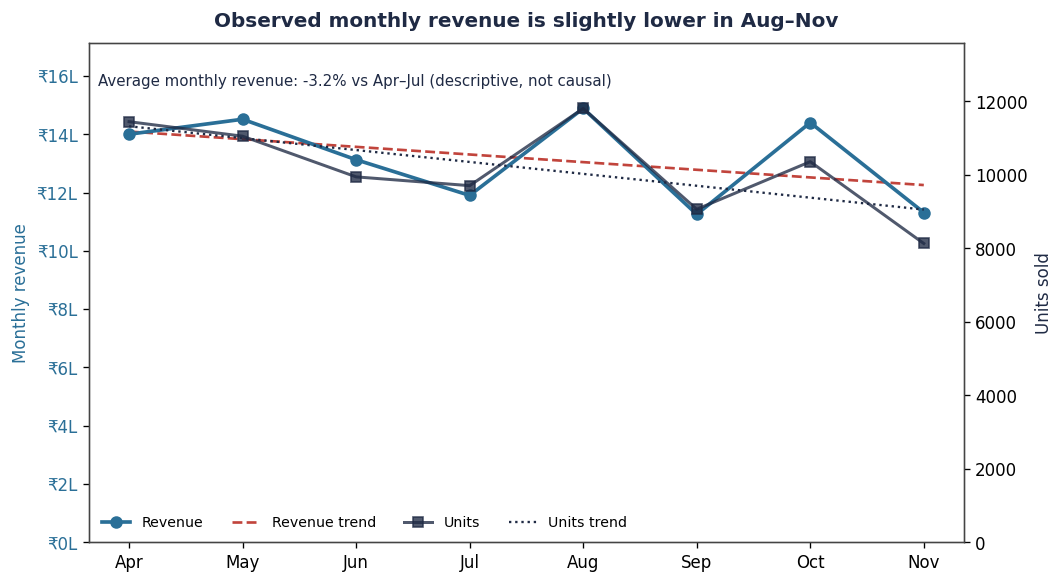

H1 (Apr-Jul) avg revenue : ₹13,38,535     H2 (Aug-Nov) avg revenue : ₹12,96,227   -> -3.2%
H1 avg units             : 10,538.5        H2 avg units             : 9,841.5      -> -6.6%
revenue CV 11.4%   units CV 12.2%
fitted slope: ₹-26,216/month, -324 units/month
realised price Apr ₹122.3  ->  Nov ₹139.1


In [3]:
m = f.groupby('Month').agg(units=('Sold Qty','sum'), rev=('Item Net Amount','sum')).reindex(MONTHS)
x = np.arange(8)

fig, ax = plt.subplots(figsize=(9.4, 5.4))
ax.plot(x, m['rev'], '-o', color=ACC, lw=2.2, ms=6.5, label='Revenue', zorder=3)
ax.plot(x, np.poly1d(np.polyfit(x, m['rev'], 1))(x), '--', color=BAD, lw=1.6, label='Revenue trend')
ax.set_ylabel('Monthly revenue', color=ACC)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'\u20b9{v/1e5:.0f}L'))
ax.tick_params(axis='y', labelcolor=ACC)

ax2 = ax.twinx()
ax2.plot(x, m['units'], '-s', color=INK, lw=1.8, ms=5.5, alpha=.78, label='Units')
ax2.plot(x, np.poly1d(np.polyfit(x, m['units'], 1))(x), ':', color=INK, lw=1.4, label='Units trend')
ax2.set_ylabel('Units sold', color=INK)

ax.set_xticks(x); ax.set_xticklabels(MLAB)
ax.set_ylim(0, m['rev'].max()*1.15); ax2.set_ylim(0, m['units'].max()*1.15)

change = (m['rev'].iloc[4:].mean() / m['rev'].iloc[:4].mean() - 1) * 100
ax.set_title('Observed monthly revenue is slightly lower in Aug\u2013Nov', fontweight='bold', color=INK, pad=10)
ax.text(.01, .94, f'Average monthly revenue: {change:+.1f}% vs Apr\u2013Jul (descriptive, not causal)',
        transform=ax.transAxes, color=INK, fontsize=9, va='top')
l1, la1 = ax.get_legend_handles_labels(); l2, la2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, la1+la2, loc='lower left', fontsize=8.5, frameon=False, ncol=4)
savefig('00_overall_trend.png'); plt.show()

h1r, h2r = m['rev'].iloc[:4].mean(), m['rev'].iloc[4:].mean()
h1u, h2u = m['units'].iloc[:4].mean(), m['units'].iloc[4:].mean()
print(f"H1 (Apr-Jul) avg revenue : \u20b9{ind(h1r)}     H2 (Aug-Nov) avg revenue : \u20b9{ind(h2r)}   -> {(h2r/h1r-1)*100:+.1f}%")
print(f"H1 avg units             : {ind(h1u,1)}        H2 avg units             : {ind(h2u,1)}      -> {(h2u/h1u-1)*100:+.1f}%")
print(f"revenue CV {m['rev'].std(ddof=1)/m['rev'].mean()*100:.1f}%   units CV {m['units'].std(ddof=1)/m['units'].mean()*100:.1f}%")
print(f"fitted slope: \u20b9{ind(np.polyfit(x,m['rev'],1)[0])}/month, {np.polyfit(x,m['units'],1)[0]:.0f} units/month")
print(f"realised price Apr \u20b9{m['rev'].iloc[0]/m['units'].iloc[0]:.1f}  ->  Nov \u20b9{m['rev'].iloc[7]/m['units'].iloc[7]:.1f}")

## 3 — Figure 4: category portfolio screen

**Formula.** Per category: `Units`, `Revenue`, `Realised price = Revenue / Units`.
Split lines are the **medians across the 38 categories** of units and realised price. Bubble area is
proportional to revenue. The x-axis is log scale for display only, because the categories span four
orders of magnitude in volume.

This is a screening tool, not a profitability ranking — I have no margin, stock or stock-out data.

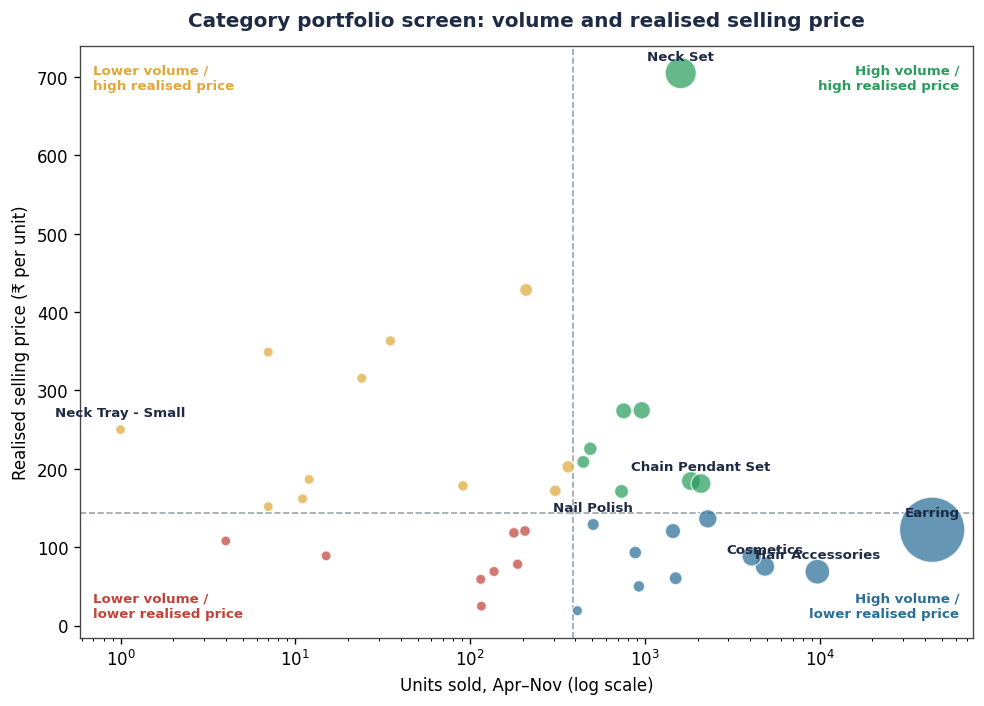

median split lines: 388 units, ₹144 realised price

                         categories     revenue  share %
quadrant                                                
high vol / high price             8  ₹26,46,233     25.1
high vol / lower price           11  ₹75,51,020     71.6
lower vol / high price           11   ₹2,60,349      2.5
lower vol / lower price           8     ₹81,447      0.8


In [4]:
mv, mp = cat['units'].median(), cat['realised'].median()

def qcol(r):
    hv, hp = r['units'] >= mv, r['realised'] >= mp
    return GOOD if (hv and hp) else ACC if hv else WARN if hp else BAD

fig, ax = plt.subplots(figsize=(9.6, 6.4))
sz = (cat['rev']/cat['rev'].max()*1500) + 35
ax.scatter(cat['units'], cat['realised'], s=sz, c=cat.apply(qcol, axis=1),
           alpha=.72, edgecolor='white', linewidth=.8, zorder=3)
ax.set_xscale('log')
ax.axvline(mv, color=GREY, ls='--', lw=1); ax.axhline(mp, color=GREY, ls='--', lw=1)

lab = cat.sort_values('rev', ascending=False).head(5)['Analysis Category'].tolist()
lab += ['NAIL POLISH', 'NECK TRAY - SMALL']
for _, r in cat.iterrows():
    if r['Analysis Category'] in lab:
        ax.annotate(r['Analysis Category'].title(), (r['units'], r['realised']), fontsize=8,
                    ha='center', va='center', color=INK, fontweight='bold',
                    xytext=(0, 10), textcoords='offset points')

for xx, yy, ha, va, txt, cl in [(.985,.97,'right','top','High volume /\nhigh realised price',GOOD),
                                (.015,.97,'left','top','Lower volume /\nhigh realised price',WARN),
                                (.985,.03,'right','bottom','High volume /\nlower realised price',ACC),
                                (.015,.03,'left','bottom','Lower volume /\nlower realised price',BAD)]:
    ax.text(xx, yy, txt, transform=ax.transAxes, ha=ha, va=va, fontsize=8, color=cl, fontweight='bold')

ax.set_xlabel('Units sold, Apr\u2013Nov (log scale)')
ax.set_ylabel('Realised selling price (\u20b9 per unit)')
ax.set_title('Category portfolio screen: volume and realised selling price', fontweight='bold', color=INK, pad=12)
savefig('01_quadrant.png'); plt.show()

cat['quadrant'] = np.where(cat['units'] >= mv,
                    np.where(cat['realised'] >= mp, 'high vol / high price', 'high vol / lower price'),
                    np.where(cat['realised'] >= mp, 'lower vol / high price', 'lower vol / lower price'))
print(f'median split lines: {mv:.0f} units, \u20b9{mp:.0f} realised price\n')
q = cat.groupby('quadrant').agg(categories=('Analysis Category','count'), revenue=('rev','sum'))
q['share %'] = (q['revenue']/cat['rev'].sum()*100).round(1)
q['revenue'] = q['revenue'].map(lambda v: '\u20b9'+ind(v))
print(q.to_string())

## 4 — Figure 5: row-normalised monthly sales mix

**Formula.** Twelve largest categories by revenue. `raw(c,m) = Σ Sold Qty`.
Displayed value = `raw(c,m) / row total × 100`, so **each row sums to 100%** and shows how that
category's own units spread across the eight months.

Normalising each row is the point: it removes the size difference between categories so their shapes
can be compared. A perfectly flat category would show 12.5% in every cell.

This does **not** establish seasonality — I only observe each calendar month once.

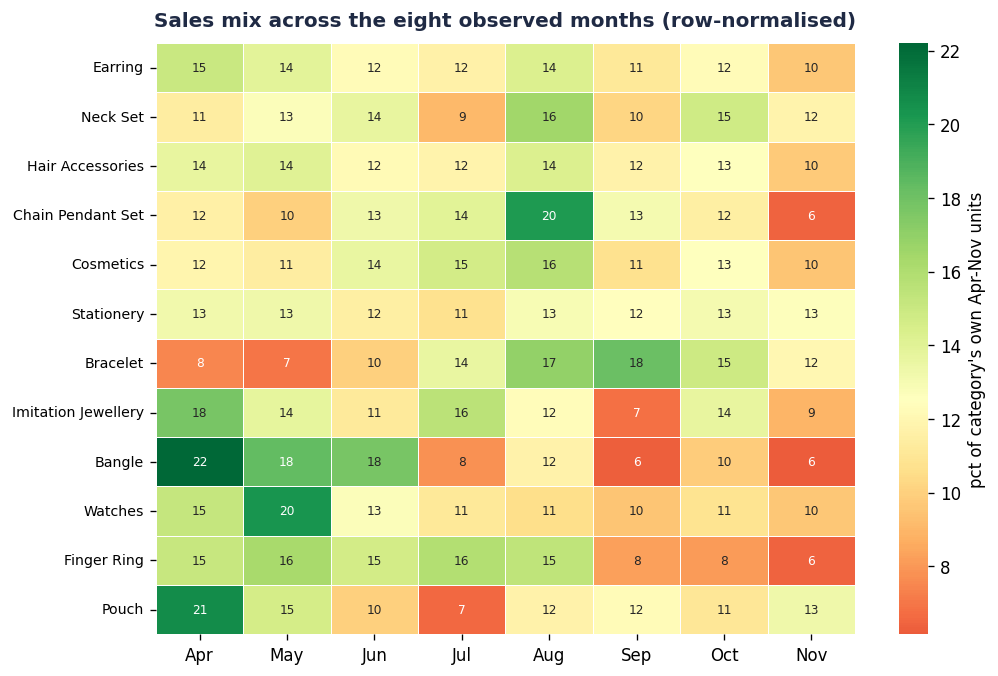

rows sum to 100%: True


In [5]:
top12 = cat.sort_values('rev', ascending=False).head(12)['Analysis Category'].tolist()
pm = (f[f['Analysis Category'].isin(top12)]
        .pivot_table(index='Analysis Category', columns='Month', values='Sold Qty',
                     aggfunc='sum', fill_value=0)
        .reindex(columns=MONTHS).reindex(top12))
pmn = pm.div(pm.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9.4, 6.4))
sns.heatmap(pmn, annot=True, fmt='.0f', cmap='RdYlGn', center=12.5, linewidths=.5, linecolor='white',
            cbar_kws={'label': "pct of category's own Apr-Nov units"}, annot_kws={'size':7.3}, ax=ax)
ax.set_xticklabels(MLAB, rotation=0)
ax.set_yticklabels([t.get_text().title() for t in ax.get_yticklabels()], rotation=0, fontsize=8.5)
ax.set_xlabel(''); ax.set_ylabel('')
ax.set_title('Sales mix across the eight observed months (row-normalised)', fontweight='bold', color=INK, pad=10)
savefig('02_heatmap_month.png'); plt.show()

print('rows sum to 100%:', bool(np.allclose(pmn.sum(axis=1), 100)))

## 5 — Figure 6: revenue mix by category and MRP band

**Formula.** Band each row on `MRP`, **left-exclusive / right-inclusive**: (0,50] … (2K,∞).
Ten largest categories. Cell text = `Σ Item Net Amount` (revenue); cell colour = `cell / row total × 100`.

The mid-term counted *products* per band, which describes the catalogue. This counts *revenue*,
which describes where the money actually comes from.

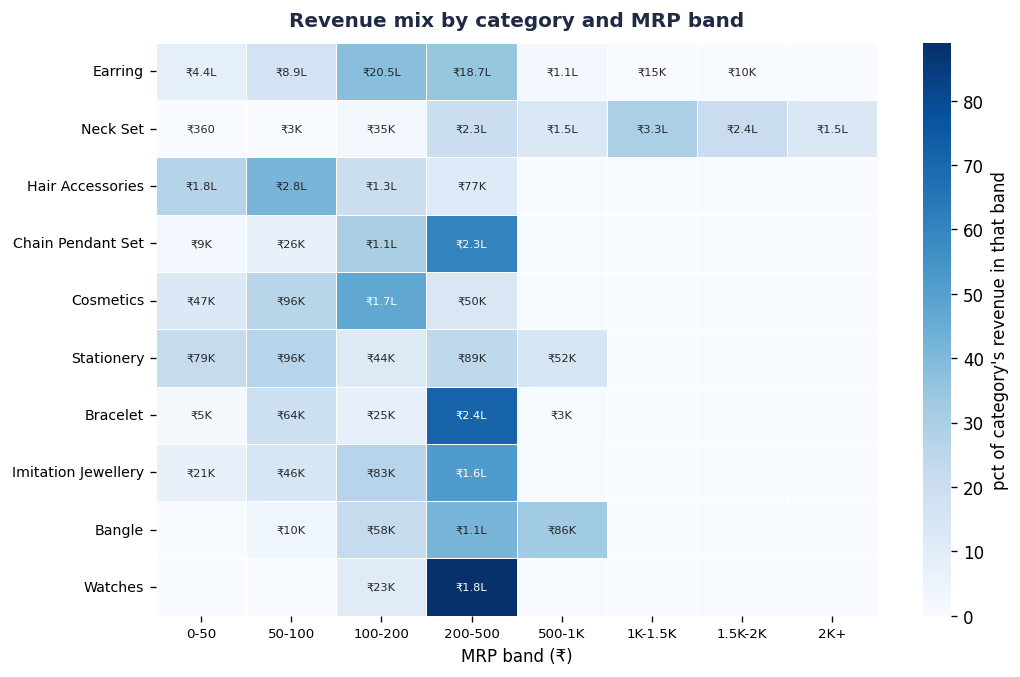

whole-store revenue share by MRP band (%):
band
0-50        8.3
50-100     15.3
100-200    30.7
200-500    34.0
500-1K      4.4
1K-1.5K     3.5
1.5K-2K     2.3
2K+         1.4

₹100-500 corridor : 64.7%
at or below ₹500 : 88.3%
above ₹1,000     : 7.2%


In [6]:
BINS = [0, 50, 100, 200, 500, 1000, 1500, 2000, np.inf]
BLAB = ['0-50','50-100','100-200','200-500','500-1K','1K-1.5K','1.5K-2K','2K+']
f['band'] = pd.cut(f['MRP'], bins=BINS, labels=BLAB, right=True)   # right-inclusive

top10 = cat.sort_values('rev', ascending=False).head(10)['Analysis Category'].tolist()
pb = (f[f['Analysis Category'].isin(top10)]
        .pivot_table(index='Analysis Category', columns='band', values='Item Net Amount',
                     aggfunc='sum', fill_value=0, observed=True)
        .reindex(index=top10, columns=BLAB, fill_value=0))
pb_share = pb.div(pb.sum(axis=1), axis=0) * 100
annot = pb.map(lambda v: inr(v) if v > 0 else '')      # pandas < 2.1 uses .applymap

fig, ax = plt.subplots(figsize=(9.7, 6.2))
sns.heatmap(pb_share, annot=annot, fmt='', cmap='Blues', linewidths=.5, linecolor='white',
            cbar_kws={'label': "pct of category's revenue in that band"}, annot_kws={'size':6.8}, ax=ax)
ax.set_xticklabels(BLAB, rotation=0, fontsize=8)
ax.set_yticklabels([t.get_text().title() for t in ax.get_yticklabels()], rotation=0, fontsize=8.5)
ax.set_xlabel('MRP band (\u20b9)'); ax.set_ylabel('')
ax.set_title('Revenue mix by category and MRP band', fontweight='bold', color=INK, pad=10)
savefig('03_heatmap_priceband.png'); plt.show()

bt = f.groupby('band', observed=True)['Item Net Amount'].sum()
share = (bt/bt.sum()*100).round(1)
print('whole-store revenue share by MRP band (%):'); print(share.to_string())
print(f"\n\u20b9100-500 corridor : {share['100-200']+share['200-500']:.1f}%")
print(f"at or below \u20b9500 : {share[['0-50','50-100','100-200','200-500']].sum():.1f}%")
print(f"above \u20b91,000     : {share[['1K-1.5K','1.5K-2K','2K+']].sum():.1f}%")

## 6 — Figure 7: change in average monthly category revenue

**Formula.** Twelve largest categories.
`H1avg = mean monthly revenue Apr–Jul`, `H2avg = mean monthly revenue Aug–Nov`,
**Change % = (H2avg / H1avg − 1) × 100**.

I use a half-against-half mean rather than a fitted slope per category, because a mean of four months
is far less sensitive to one unusual month than a regression through eight points.

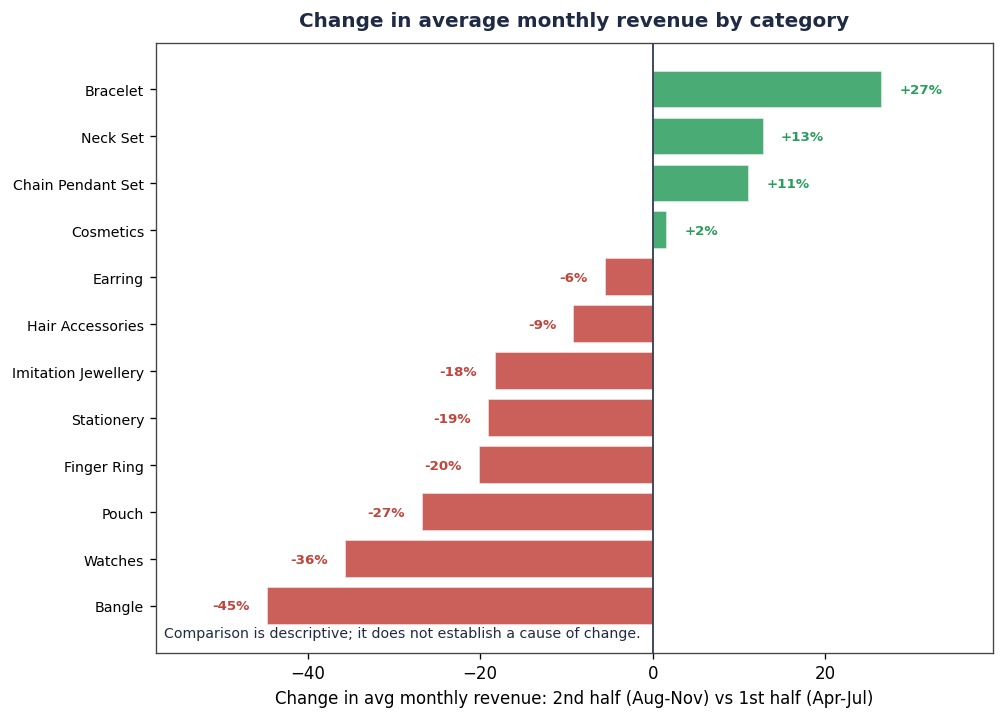

                cat        h1        h2    chg
           BRACELET   ₹37,315   ₹47,235 +26.6%
           NECK SET ₹1,32,652 ₹1,49,720 +12.9%
  CHAIN PENDANT SET   ₹44,928   ₹49,943 +11.2%
          COSMETICS   ₹45,430   ₹46,208  +1.7%
            EARRING ₹6,91,690 ₹6,53,130  -5.6%
   HAIR ACCESSORIES   ₹87,336   ₹79,301  -9.2%
IMITATION JEWELLERY   ₹42,911   ₹35,046 -18.3%
         STATIONERY   ₹49,799   ₹40,296 -19.1%
        FINGER RING   ₹24,246   ₹19,370 -20.1%
              POUCH   ₹18,156   ₹13,303 -26.7%
            WATCHES   ₹31,511   ₹20,276 -35.7%
             BANGLE   ₹42,429   ₹23,440 -44.8%


In [7]:
rows = []
for cname in top12:
    s = f[f['Analysis Category'] == cname].groupby('Month')['Item Net Amount'].sum().reindex(MONTHS).fillna(0)
    h1, h2 = s.iloc[:4].mean(), s.iloc[4:].mean()
    rows.append((cname, s.sum(), (h2/h1 - 1)*100 if h1 else 0, h1, h2))
td = pd.DataFrame(rows, columns=['cat','rev','chg','h1','h2']).sort_values('chg')

fig, ax = plt.subplots(figsize=(9, 6.6))
ax.barh(range(len(td)), td['chg'], color=[GOOD if v > 0 else BAD for v in td['chg']],
        alpha=.85, edgecolor='white')
ax.set_yticks(range(len(td))); ax.set_yticklabels([c.title() for c in td['cat']], fontsize=8.5)
ax.axvline(0, color=INK, lw=1)
for i, v in enumerate(td['chg']):
    ax.text(v + (2 if v >= 0 else -2), i, f'{v:+.0f}%', va='center',
            ha='left' if v >= 0 else 'right', fontsize=8, fontweight='bold', color=GOOD if v > 0 else BAD)
ax.set_xlabel('Change in avg monthly revenue: 2nd half (Aug-Nov) vs 1st half (Apr-Jul)')
ax.set_title('Change in average monthly revenue by category', fontweight='bold', color=INK, pad=10)
ax.text(.01, .02, 'Comparison is descriptive; it does not establish a cause of change.',
        transform=ax.transAxes, fontsize=8.5, color=INK, va='bottom')
ax.margins(x=.18)
savefig('04_category_trend.png'); plt.show()

out = td.sort_values('chg', ascending=False)[['cat','h1','h2','chg']].copy()
out['h1'] = out['h1'].map(lambda v: '\u20b9'+ind(v)); out['h2'] = out['h2'].map(lambda v: '\u20b9'+ind(v))
out['chg'] = out['chg'].map(lambda v: f'{v:+.1f}%')
print(out.to_string(index=False))

## 7 — Figure 8 and Table 4: ABC classification

**Formula.** Sort categories by revenue, descending. `Cumulative % = running total / grand total × 100`.

- **A** = up to and including the category that first reaches 80%
- **B** = the following categories up to and including the one that first reaches 95%
- **C** = the remainder

I use the 80/95 rule rather than an arbitrary top-ten because it states the cut point explicitly and
anyone can re-run it at other thresholds.

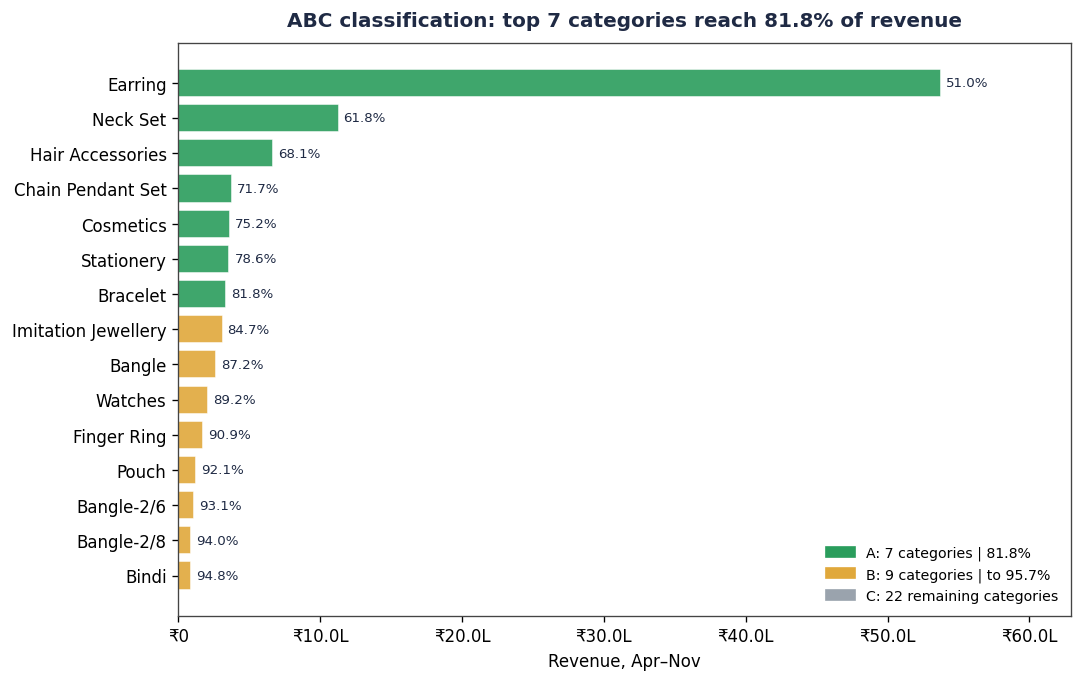

--- Table 4: ABC bands ---
     categories     revenue  revenue share %  U-ID share %
abc                                                       
A             7  ₹86,19,942             81.8          82.7
B             9  ₹14,65,441             13.9          11.9
C            22   ₹4,53,664              4.3           5.4

--- full ranking (all 38 categories) ---
  Analysis Category        rev   units  skus realised     cum abc
            EARRING ₹53,79,283 43989.0  3416   ₹122.3  51.04%   A
           NECK SET ₹11,29,491  1602.0   523   ₹705.1  61.76%   A
   HAIR ACCESSORIES  ₹6,66,549  9695.0   254    ₹68.8  68.08%   A
  CHAIN PENDANT SET  ₹3,79,486  2094.0   174   ₹181.2  71.68%   A
          COSMETICS  ₹3,66,555  4861.0   152    ₹75.4  75.16%   A
         STATIONERY  ₹3,60,379  4082.0   163    ₹88.3  78.58%   A
           BRACELET  ₹3,38,201  1833.0   123   ₹184.5  81.79%   A
IMITATION JEWELLERY  ₹3,11,829  2289.0   136   ₹136.2  84.75%   B
             BANGLE  ₹2,63,474   959.0   1

In [8]:
cs = cat.sort_values('rev', ascending=False).reset_index(drop=True)
cs['cum'] = cs['rev'].cumsum() / cs['rev'].sum() * 100
a_end = int(np.searchsorted(cs['cum'].to_numpy(), 80, side='left'))
b_end = int(np.searchsorted(cs['cum'].to_numpy(), 95, side='left'))
A, B = a_end + 1, b_end - a_end
cs['abc'] = 'C'
cs.loc[:a_end, 'abc'] = 'A'
cs.loc[a_end+1:b_end, 'abc'] = 'B'

show = cs.head(min(15, len(cs))).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.6, 6.2))
bars = ax.barh(show['Analysis Category'].str.title(), show['rev'],
               color=show['abc'].map({'A':GOOD,'B':WARN,'C':GREY}), alpha=.9, edgecolor='white')
ax.xaxis.set_major_formatter(FuncFormatter(inr))
ax.set_xlabel('Revenue, Apr\u2013Nov'); ax.set_ylabel('')
ax.set_title(f'ABC classification: top {A} categories reach {cs.loc[a_end,"cum"]:.1f}% of revenue',
             fontweight='bold', color=INK, pad=10)
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in show['cum']], padding=3, fontsize=8, color=INK)
ax.margins(x=.17)
ax.legend(handles=[Patch(color=GOOD, label=f'A: {A} categories | {cs.loc[a_end,"cum"]:.1f}%'),
                   Patch(color=WARN, label=f'B: {B} categories | to {cs.loc[b_end,"cum"]:.1f}%'),
                   Patch(color=GREY, label=f'C: {len(cs)-A-B} remaining categories')],
          loc='lower right', fontsize=8.5, frameon=False)
savefig('05_abc_pareto.png'); plt.show()

print('--- Table 4: ABC bands ---')
band = cs.groupby('abc').agg(categories=('Analysis Category','count'), revenue=('rev','sum'), uids=('skus','sum'))
band['revenue share %'] = (band['revenue']/cs['rev'].sum()*100).round(1)
band['U-ID share %']    = (band['uids']/cs['skus'].sum()*100).round(1)
band['revenue']         = band['revenue'].map(lambda v: '\u20b9'+ind(v))
print(band[['categories','revenue','revenue share %','U-ID share %']].to_string())
print('\n--- full ranking (all 38 categories) ---')
full = cs[['Analysis Category','rev','units','skus','realised','cum','abc']].copy()
full['rev'] = full['rev'].map(lambda v: '\u20b9'+ind(v))
full['realised'] = full['realised'].map(lambda v: f'\u20b9{v:,.1f}')
full['cum'] = full['cum'].map(lambda v: f'{v:.2f}%')
print(full.to_string(index=False))

## 8 — Figure 9 and Table 5: earring sub-type deep dive

**Formula.** Filter `Analysis Category == 'EARRING'`. Per sub-type: `Revenue = Σ Item Net Amount`;
`share of earrings = Rev(sub) / Σ earring revenue × 100`;
`share of store = Rev(sub) / total full-month merchandise revenue × 100`.

One category is half the business, so it gets its own exhibit.

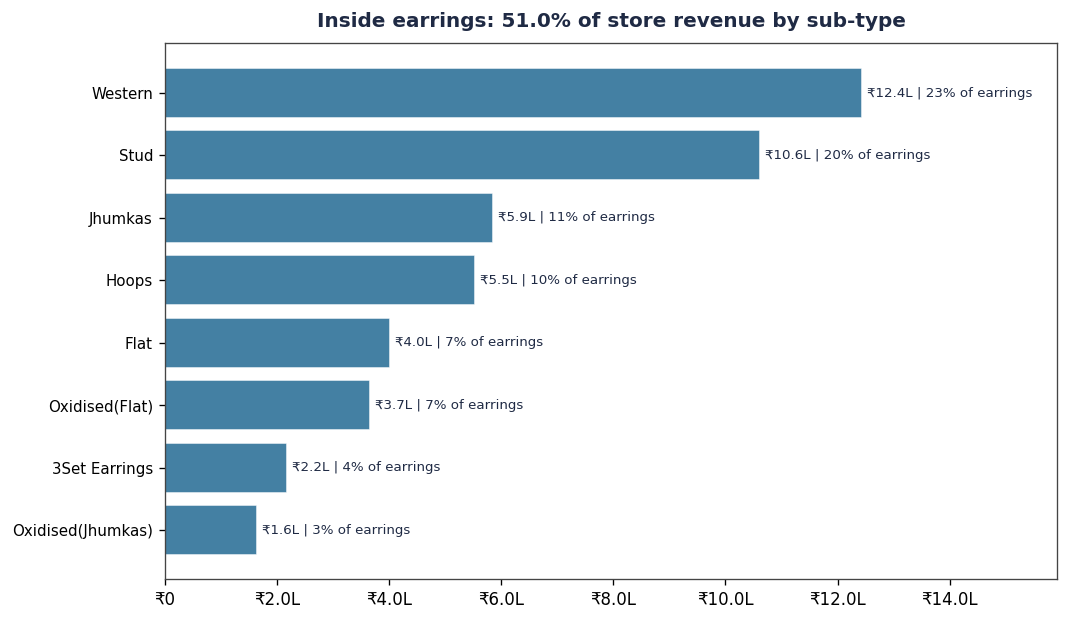

--- Table 5: earring sub-types ---
                          rev    units  skus  realised  % of earrings  % of store
SUB CATEGORY                                                                     
WESTERN            ₹12,43,841  10468.0   697     118.8           23.1        11.8
STUD               ₹10,62,246   9416.0   633     112.8           19.7        10.1
JHUMKAS             ₹5,86,215   7006.0   328      83.7           10.9         5.6
HOOPS               ₹5,53,626   4507.0   380     122.8           10.3         5.3
FLAT                ₹4,01,593   2404.0   377     167.1            7.5         3.8
OXIDISED(FLAT)      ₹3,65,606   2010.0   172     181.9            6.8         3.5
3SET EARRINGS       ₹2,17,839   1246.0    66     174.8            4.0         2.1
OXIDISED(JHUMKAS)   ₹1,64,284    902.0   101     182.1            3.1         1.6

earrings: ₹53,79,283 = 51.0% of merchandise revenue
          43,989 units, 3,416 U-IDs, 37 sub-types, realised price ₹122.29
top five: 71.5% of

In [9]:
e   = f[f['Analysis Category'] == 'EARRING']
sub = (e.groupby('SUB CATEGORY')
         .agg(rev=('Item Net Amount','sum'), units=('Sold Qty','sum'), skus=('U-ID','nunique'))
         .sort_values('rev', ascending=False))
tot   = sub['rev'].sum()
store = f['Item Net Amount'].sum()
top   = sub.head(8)

fig, ax = plt.subplots(figsize=(9.6, 5.8))
bars = ax.barh(range(len(top))[::-1], top['rev'], color=ACC, alpha=.88, edgecolor='white')
ax.set_yticks(range(len(top))[::-1]); ax.set_yticklabels([s.title() for s in top.index], fontsize=9)
ax.xaxis.set_major_formatter(FuncFormatter(inr))
ax.bar_label(bars, labels=[f'{inr(r)} | {r/tot*100:.0f}% of earrings' for r in top['rev']],
             padding=3, fontsize=8, color=INK)
ax.set_title(f'Inside earrings: {tot/store*100:.1f}% of store revenue by sub-type',
             fontweight='bold', color=INK, pad=10)
ax.margins(x=.28)
savefig('06_earring_deepdive.png'); plt.show()

print('--- Table 5: earring sub-types ---')
t5 = top.copy()
t5['realised']      = (t5['rev']/t5['units']).round(1)
t5['% of earrings'] = (t5['rev']/tot*100).round(1)
t5['% of store']    = (t5['rev']/store*100).round(1)
t5['rev']           = t5['rev'].map(lambda v: '\u20b9'+ind(v))
print(t5.to_string())
print(f"\nearrings: \u20b9{ind(tot)} = {tot/store*100:.1f}% of merchandise revenue")
print(f"          {ind(sub['units'].sum())} units, {ind(e['U-ID'].nunique())} U-IDs, {len(sub)} sub-types, realised price \u20b9{tot/sub['units'].sum():.2f}")
print(f"top five: {sub['rev'].head(5).sum()/tot*100:.1f}% of earrings = {sub['rev'].head(5).sum()/store*100:.1f}% of the whole store")

## 9 — Influencer half: corrected scoring, Figures 10–11, Tables 6–7

At the exploratory stage I built a `Scope` column that simply multiplied peak reel views by an ability
figure, **without scaling either**. Peak views in the sheet run from about 3,500 to 7.1 million, so that
product was decided almost entirely by the largest view count and the ranking was really just a ranking
by views. I discard that column here and recompute on min–max scaled inputs.

**Formulas**

```
Ability       = followers ÷ number of posts
View score    = min–max scaled peak reel views
Ability score = min–max scaled Ability
Scope score   = (0.60 × view score + 0.40 × ability score) × 100
```

The 0.60 / 0.40 split is my judgement, not something the data chose.

**One honest weakness:** min–max scaling is sensitive to outliers at both ends. Candidate I sits at the
top largely because of one 7.1 million-view reel, and candidates G and N score high on the ability term
only because they have posted 5 and 6 times — a small denominator inflates the ratio. I therefore add a
**≥ 15 posts** screen before shortlisting. That screen is my own cut-off; change the constant to test it.

In [10]:
inf = pd.read_excel(INFL_PATH)
inf.columns = [c.strip() for c in inf.columns]
inf = inf.rename(columns={'most viewed count(in K)':'views', 'Number of posts':'posts'})

inf['Ability']      = inf['followers'] / inf['posts']
inf['ViewScore']    = (inf['views']   - inf['views'].min())   / (inf['views'].max()   - inf['views'].min())
inf['AbilityScore'] = (inf['Ability'] - inf['Ability'].min()) / (inf['Ability'].max() - inf['Ability'].min())
inf['Scope']        = (0.60*inf['ViewScore'] + 0.40*inf['AbilityScore']) * 100

MIN_POSTS = 15                      # my own screen - change this to test it
inf['Base'] = np.where(inf['posts'] >= MIN_POSTS, 'pass', 'thin')
inf = inf.sort_values('Scope', ascending=False)

SHORTLIST = inf[inf['Base'] == 'pass'].head(6)['Proxy name'].tolist()
inf['tier'] = np.where(inf['Proxy name'].isin(SHORTLIST), 'Shortlist',
                np.where(inf['Base'] == 'thin', 'Thin content base', 'Not shortlisted'))

print('--- Table 6: recalculated scorecard ---')
show = inf[['Proxy name','gender','pass out','followers','posts','views','Ability',
            'ViewScore','AbilityScore','Scope','tier']].copy()
show['views'] = (show['views']*1000).round(0).astype(int)
print(show.round(3).to_string(index=False))
print(f'\nshortlist (score rank, >= {MIN_POSTS} posts): {", ".join(SHORTLIST)}')

--- Table 6: recalculated scorecard ---
Proxy name gender pass out  followers  posts   views  Ability  ViewScore  AbilityScore  Scope              tier
         I      F  NIFT'28       2092     40 7100000   52.300      1.000         0.114 64.553         Shortlist
         G      F  Nift’27       1672      5    9510  334.400      0.001         1.000 40.050 Thin content base
         N      F  Nift’27       1291      6    5112  215.167      0.000         0.625 25.031 Thin content base
         E      M  NIFT'26       1896     22 1600000   86.182      0.225         0.220 22.309         Shortlist
         M      F  NIFT'29       2630     90 2100000   29.222      0.295         0.041 19.379         Shortlist
         K      F  NIFT'28       2050     39 1000000   52.564      0.140         0.115 13.012         Shortlist
         F      F  Nift’27       1241     47 1000000   26.404      0.140         0.032  9.725         Shortlist
         J      F  NIFT'28       1770     22   18600   80.455   

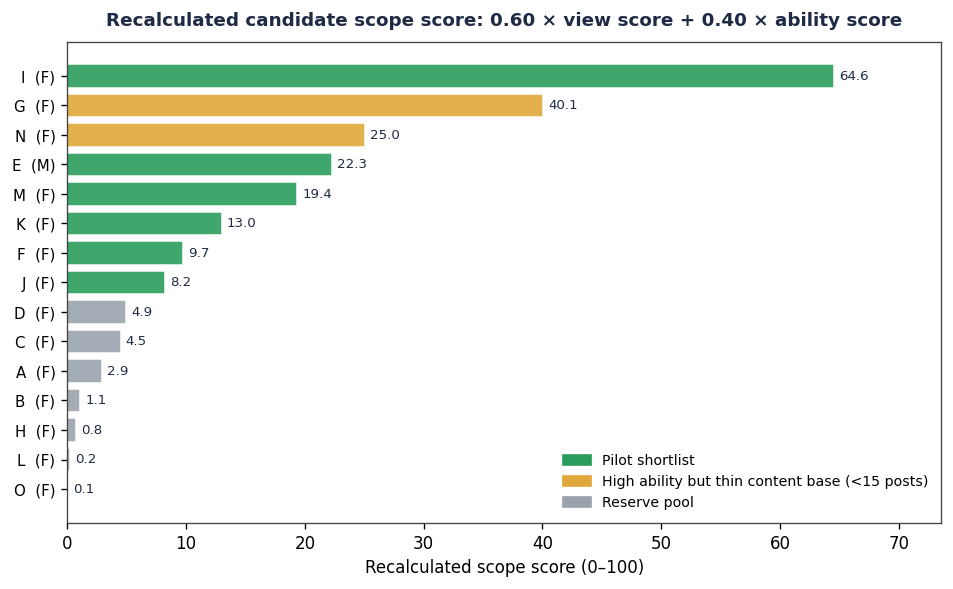

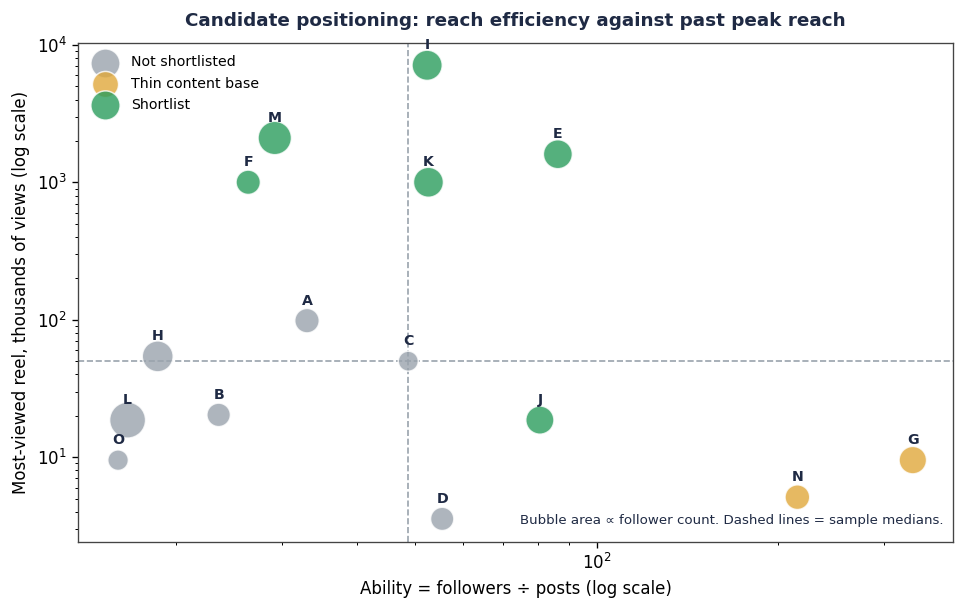

In [11]:
col = {'Shortlist':GOOD, 'Thin content base':WARN, 'Not shortlisted':GREY}

# --- Figure 10: score ranking
fig, ax = plt.subplots(figsize=(9.4, 5.2))
o = inf.iloc[::-1]
b = ax.barh(range(len(o)), o['Scope'], color=[col[t] for t in o['tier']], alpha=.9, edgecolor='white')
ax.set_yticks(range(len(o)))
ax.set_yticklabels([f"{p}  ({g})" for p, g in zip(o['Proxy name'], o['gender'])], fontsize=9)
ax.bar_label(b, labels=[f'{v:.1f}' for v in o['Scope']], padding=3, fontsize=8, color=INK)
ax.set_xlabel('Recalculated scope score (0\u2013100)')
ax.set_title('Recalculated candidate scope score: 0.60 \u00d7 view score + 0.40 \u00d7 ability score',
             fontweight='bold', color=INK, pad=10, fontsize=11)
ax.margins(x=.14)
ax.legend(handles=[Patch(color=GOOD, label='Pilot shortlist'),
                   Patch(color=WARN, label=f'High ability but thin content base (<{MIN_POSTS} posts)'),
                   Patch(color=GREY, label='Reserve pool')],
          loc='lower right', fontsize=8.5, frameon=False)
savefig('07_scope_scores.png'); plt.show()

# --- Figure 11: positioning
fig, ax = plt.subplots(figsize=(9.4, 5.4))
for t in ['Not shortlisted','Thin content base','Shortlist']:
    s = inf[inf['tier'] == t]
    ax.scatter(s['Ability'], s['views'], s=(s['followers']/inf['followers'].max()*420)+45,
               c=col[t], alpha=.8, edgecolor='white', linewidth=.9, label=t, zorder=3)
for _, r in inf.iterrows():
    ax.annotate(r['Proxy name'], (r['Ability'], r['views']), fontsize=8.5, ha='center', va='center',
                color=INK, fontweight='bold', xytext=(0, 12), textcoords='offset points')
ax.set_xscale('log'); ax.set_yscale('log')
ax.axvline(inf['Ability'].median(), color=GREY, ls='--', lw=1)
ax.axhline(inf['views'].median(),   color=GREY, ls='--', lw=1)
ax.set_xlabel('Ability = followers \u00f7 posts (log scale)')
ax.set_ylabel('Most-viewed reel, thousands of views (log scale)')
ax.set_title('Candidate positioning: reach efficiency against past peak reach',
             fontweight='bold', color=INK, pad=10, fontsize=11)
ax.text(.99, .03, 'Bubble area \u221d follower count. Dashed lines = sample medians.',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=8, color=INK)
ax.legend(loc='upper left', fontsize=8.5, frameon=False)
savefig('08_infl_positioning.png'); plt.show()

## 10 — Self-audit

Two things are worth checking before any of these numbers go into the report.

**The reconciliation bridge.** My mid-term report quoted a grand total of ₹1,07,05,105.92 for the whole
file. This notebook quotes ₹1,05,39,048 for April–November merchandise. Those are not in conflict — the
difference is exactly the December part-week plus the packaging I excluded, and the bridge below proves
it. The same applies to units: the mid-term's 82,934 is this notebook's 81,520 plus 1,076 December units
plus 338 packaging units.

**Headline figures.** Everything in Table 1 of the report, printed here so it can be compared directly.

In [12]:
grand   = df['Item Net Amount'].sum()
dec_rev = df.loc[df['Month']=='December 2025','Item Net Amount'].sum()
exc_rev = excluded['Item Net Amount'].sum()
bridge  = grand - dec_rev - exc_rev
target  = cat['rev'].sum()

print('RECONCILIATION BRIDGE (revenue)')
print(f"  grand total, all months, all labels (mid-term figure)   \u20b9{ind(grand,2):>16s}")
print(f"  less December 2025 partial week                        -\u20b9{ind(dec_rev,2):>15s}")
print(f"  less non-merchandise packaging, Apr-Nov                -\u20b9{ind(exc_rev,2):>15s}")
print(f"  {'-'*68}")
print(f"  = Apr-Nov customer-merchandise revenue                  \u20b9{ind(bridge,2):>16s}")
print(f"  figure used throughout the report                       \u20b9{ind(target,2):>16s}")
print(f"  BRIDGE TIES: {abs(bridge-target) < 0.01}")

gu   = df['Sold Qty'].sum()
decu = df.loc[df['Month']=='December 2025','Sold Qty'].sum()
excu = excluded['Sold Qty'].sum()
print('\nRECONCILIATION BRIDGE (units)')
print(f"  mid-term total units {ind(gu)} = {ind(gu-decu-excu)} merchandise + {ind(decu)} December + {ind(excu)} packaging")
print(f"  BRIDGE TIES: {abs((gu-decu-excu) - f['Sold Qty'].sum()) < 1e-9}")

print('\nHEADLINE FIGURES (report Table 1)')
print(f"  customer-merchandise revenue        \u20b9{ind(target)}")
print(f"  net units sold                       {ind(f['Sold Qty'].sum())}")
print(f"  active product identifiers (U-IDs)   {ind(f['U-ID'].nunique())}")
print(f"  average realised price per unit     \u20b9{target/f['Sold Qty'].sum():.2f}")
print(f"  merchandise categories               {len(cat)}")
print(f"  categories reaching 80% of revenue   {A}")
print(f"  earring share of revenue             {tot/store*100:.1f}%")
print(f"  Aug-Nov vs Apr-Jul average revenue   {(h2r/h1r-1)*100:+.1f}%")

print('\nRETURNS (left in the file on purpose \u2014 they net out automatically)')
w = df[df['Month'].isin(MONTHS)]
print(f"  {int((w['Sold Qty']<0).sum())} return rows, removing {w.loc[w['Sold Qty']<0,'Sold Qty'].sum():.0f} units and \u20b9{ind(abs(w.loc[w['Sold Qty']<0,'Item Net Amount'].sum()))}")

RECONCILIATION BRIDGE (revenue)
  grand total, all months, all labels (mid-term figure)   ₹  1,07,05,105.92
  less December 2025 partial week                        -₹    1,56,326.00
  less non-merchandise packaging, Apr-Nov                -₹       9,732.00
  --------------------------------------------------------------------
  = Apr-Nov customer-merchandise revenue                  ₹  1,05,39,047.92
  figure used throughout the report                       ₹  1,05,39,047.92
  BRIDGE TIES: True

RECONCILIATION BRIDGE (units)
  mid-term total units 82,934 = 81,520 merchandise + 1,076 December + 338 packaging
  BRIDGE TIES: True

HEADLINE FIGURES (report Table 1)
  customer-merchandise revenue        ₹1,05,39,048
  net units sold                       81,520
  active product identifiers (U-IDs)   5,813
  average realised price per unit     ₹129.28
  merchandise categories               38
  categories reaching 80% of revenue   7
  earring share of revenue             51.0%
  Aug-Nov vs 

---

### Limits I want on the record

- **Eight months describe; they do not explain.** One observation of each calendar month cannot separate
  a seasonal pattern from a buying decision, a supply gap or a display change. Nothing above should be
  read as a seasonal finding.
- **No cost, stock or stock-out data.** Margin cannot be computed, so no category is assessed for
  profitability and no low-volume category is called weak or a candidate for removal.
- **No customer or bill identifiers.** Basket size, repeat rate and attachment rate are not measurable
  from this extract, which is also why RFM and clustering were not attempted.
- **The influencer sheet is fifteen hand-collected accounts** from one campus network with unverified
  audience geography. The shortlist is a starting point for a pilot, not evidence that the pilot works.

### Files this notebook writes

`charts/00_overall_trend.png` · `01_quadrant.png` · `02_heatmap_month.png` · `03_heatmap_priceband.png` ·
`04_category_trend.png` · `05_abc_pareto.png` · `06_earring_deepdive.png` · `07_scope_scores.png` ·
`08_infl_positioning.png`